# Dataset understanding and relational audit

Mann Raval, Kaggle version 3, CC BY 4.0. These are dataset findings; verified market provenance is absent. No source data is fabricated.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert ROOT.name == 'data_science_project_dsai'
sys.path.insert(0, str(ROOT / 'src'))
from jobmarket.data import load_jobs
j = load_jobs()
print('Jobs:', j.shape)


Jobs: (50000, 18)


In [2]:
print(j.dtypes.to_string())
print(j.nunique().to_string())
print(j.isna().sum().to_string())

job_id                      str
job_title                   str
company_type                str
industry                    str
country                     str
city                        str
remote_type                 str
experience_level            str
min_experience_years      int64
salary_min_usd            int64
salary_max_usd            int64
employment_type             str
posted_year               int64
company_size                str
standardized_title          str
role_category               str
salary_mid_usd          float64
salary_width_usd          int64
job_id                  50000
job_title                   6
company_type                3
industry                    5
country                     6
city                       24
remote_type                 3
experience_level            3
min_experience_years        3
salary_min_usd          30192
salary_max_usd          36463
employment_type             1
posted_year                 7
company_size                3
stan

In [3]:
quality = json.loads((ROOT / 'reports/data_quality.json').read_text())
print(json.dumps({k: quality[k] for k in ['jobs','skills_rows','matched_jobs','matched_job_fraction','orphan_skill_rows','trends_count_matches']}, indent=2))

{
  "jobs": 50000,
  "skills_rows": 224605,
  "matched_jobs": 2050,
  "matched_job_fraction": 0.041,
  "orphan_skill_rows": 215345,
  "trends_count_matches": 0
}


## Target proxies

These mappings must not be used as predictors for the corresponding task.

In [4]:
print(pd.crosstab(j.experience_level, j.min_experience_years).to_string())
print(pd.crosstab(j.remote_type, j.city.eq('Remote')).to_string())

min_experience_years      0      2      5
experience_level                         
Entry                 16628      0      0
Mid                       0  16695      0
Senior                    0      0  16677
city         False  True 
remote_type              
Hybrid       16984      0
Onsite       16538      0
Remote           0  16478


In [5]:
print(j.groupby('experience_level').salary_mid_usd.agg(['count','mean','median','std']).to_string())
print(j.groupby('country').salary_mid_usd.agg(['count','mean','median']).to_string())

                  count           mean    median          std
experience_level                                             
Entry             16628   67473.507698   67469.5  4204.690933
Mid               16695  107507.124049  107541.5  4190.282414
Senior            16677  157490.178359  157468.5  4200.073875
           count           mean     median
country                                   
Australia   8276  111485.412337  107806.50
Canada      8303  110314.312839  107476.50
Germany     8345  110897.890294  107532.50
India       8350  110396.954910  107285.25
UK          8452  111039.290582  107637.75
USA         8274  111057.537165  107686.50


## Skill relationship coverage

Use exact matching only. Missing links are unknown labels; not empty skill sets.

In [6]:
s = pd.read_csv(ROOT / 'data/processed/job_skills.csv')
print(j.assign(has_skills=j.job_id.isin(s.job_id)).groupby(['country','posted_year']).has_skills.agg(['count','mean']).to_string())

                       count      mean
country   posted_year                 
Australia 2020          1207  0.043082
          2021          1159  0.039689
          2022          1163  0.034394
          2023          1147  0.032258
          2024          1242  0.043478
          2025          1155  0.064935
          2026          1203  0.037406
Canada    2020          1160  0.046552
          2021          1243  0.040225
          2022          1160  0.044828
          2023          1182  0.042301
          2024          1254  0.039872
          2025          1094  0.044790
          2026          1210  0.036364
Germany   2020          1226  0.039967
          2021          1219  0.036916
          2022          1184  0.031250
          2023          1173  0.045183
          2024          1200  0.041667
          2025          1180  0.043220
          2026          1163  0.031814
India     2020          1210  0.035537
          2021          1169  0.038494
          2022          1

### Salary Distribution

Regenerate with `job-market analyze`.

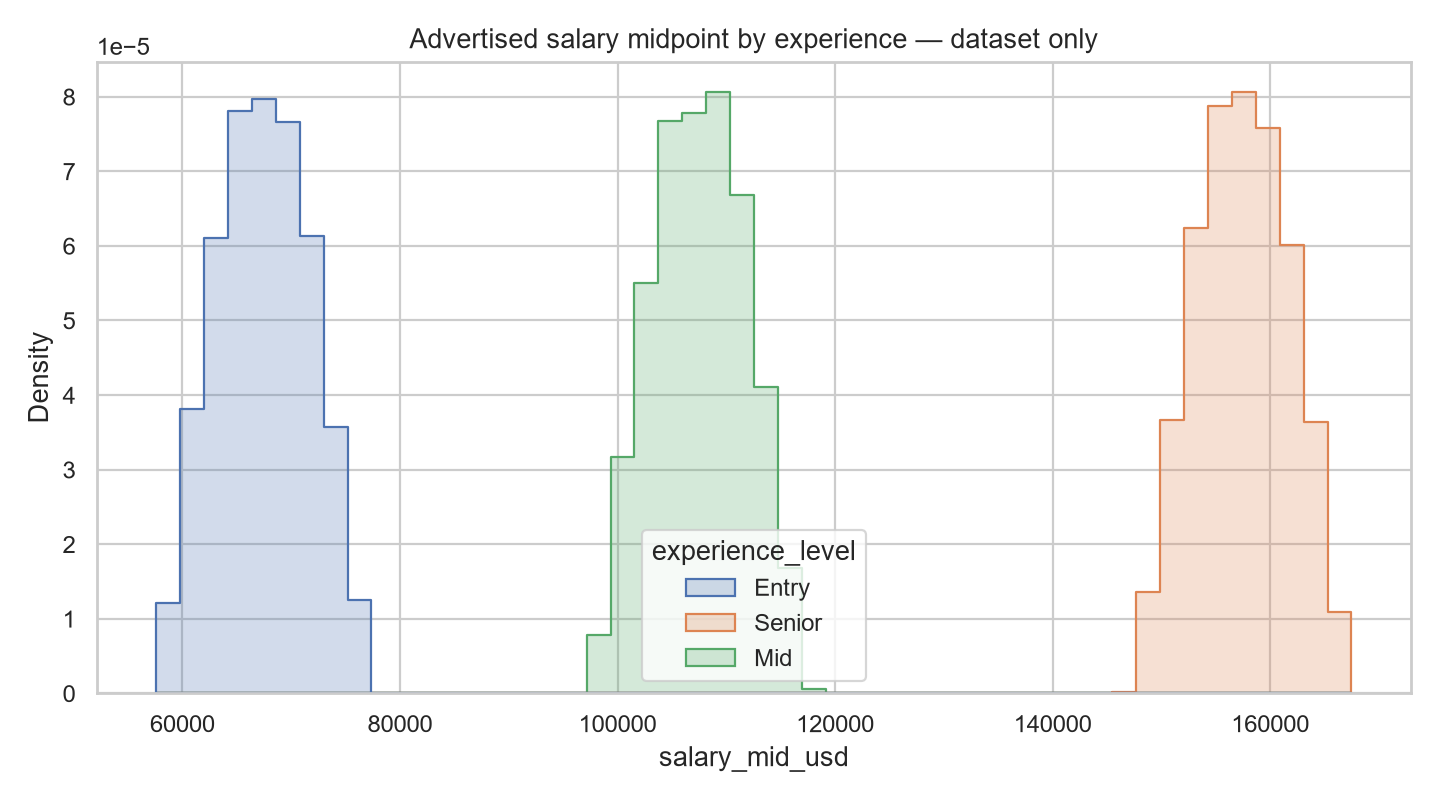

In [7]:
# Figure generated by the reproducible analysis pipeline: reports/figures/salary_distribution.png


### Remote Trends

Regenerate with `job-market analyze`.

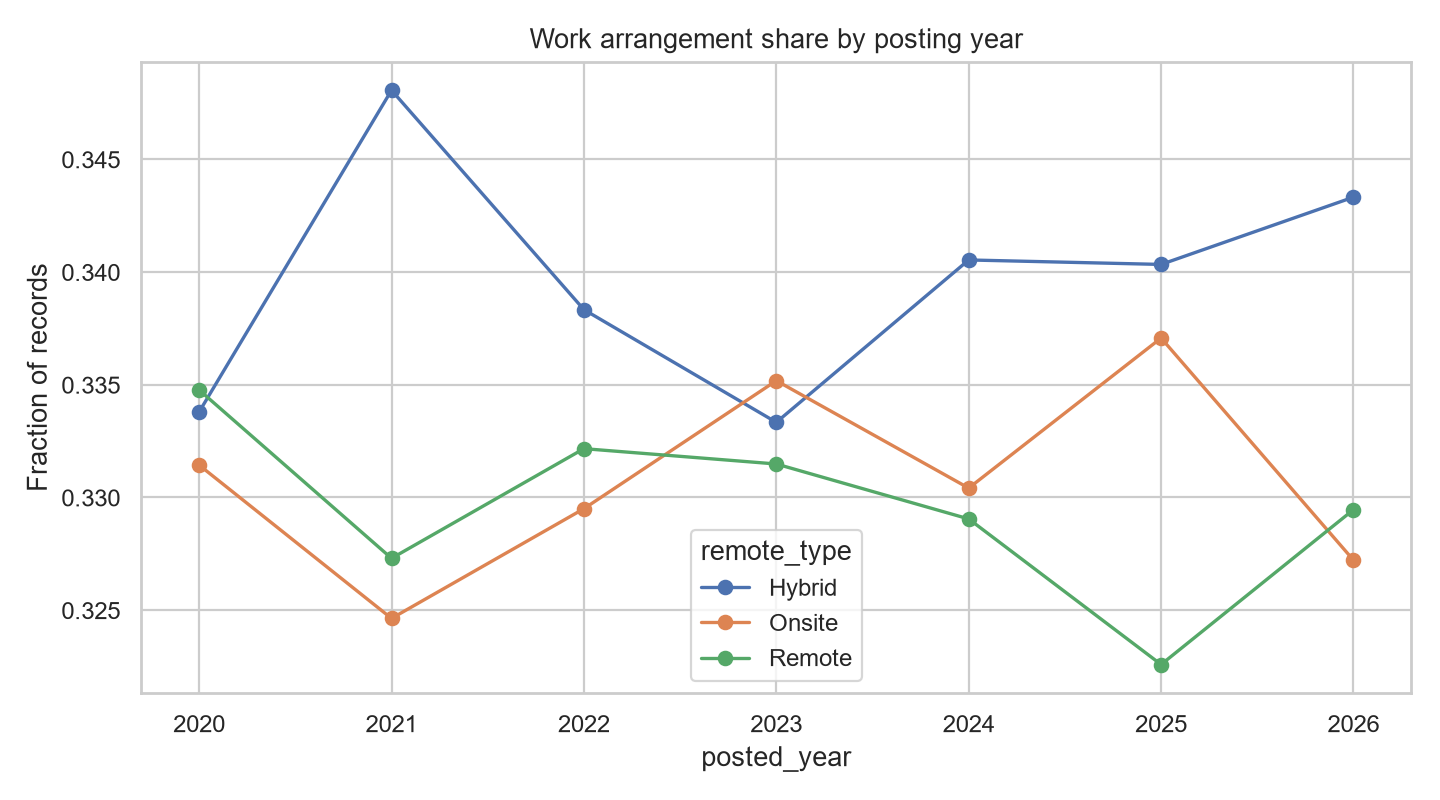

In [8]:
# Figure generated by the reproducible analysis pipeline: reports/figures/remote_trends.png


### Skills Demand

Regenerate with `job-market analyze`.

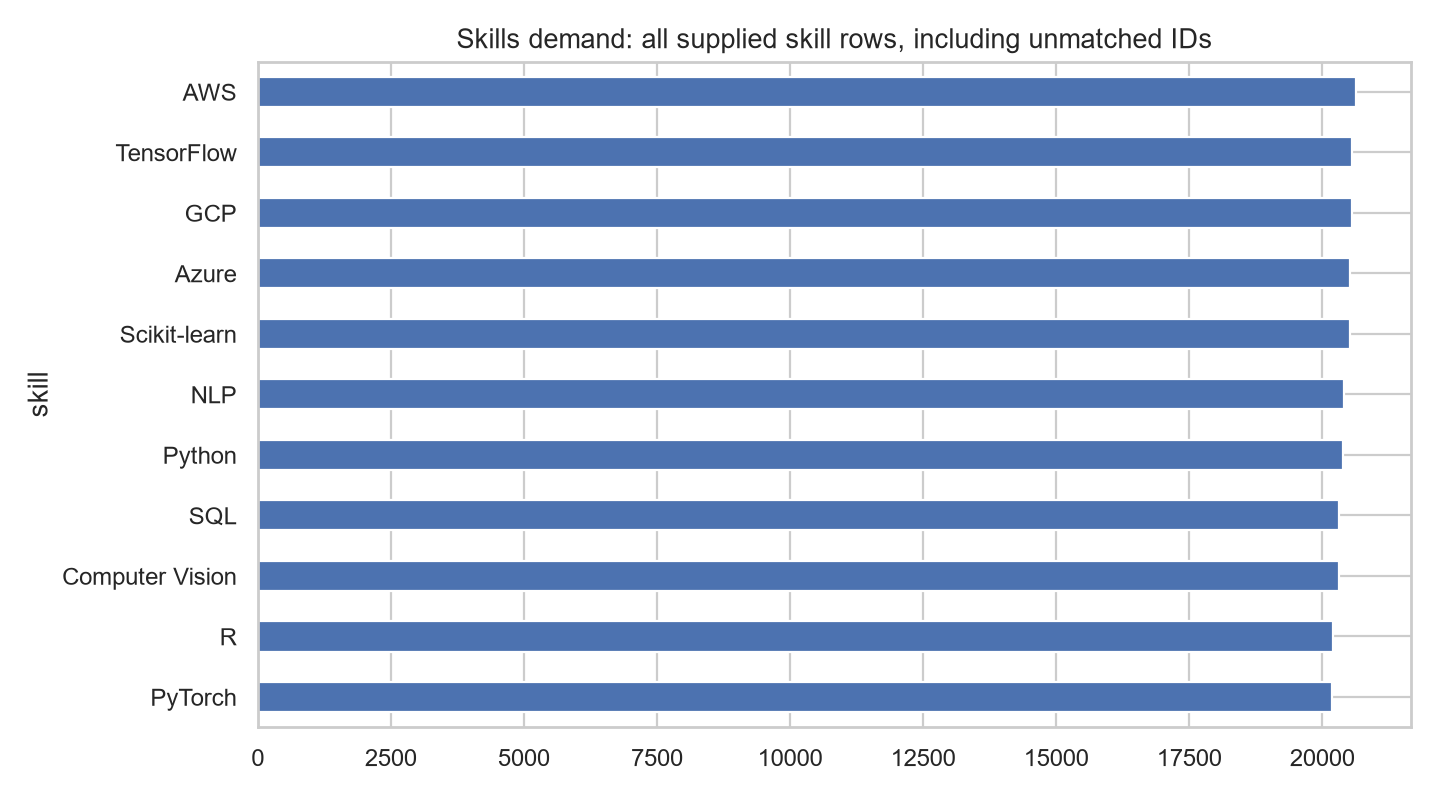

In [9]:
# Figure generated by the reproducible analysis pipeline: reports/figures/skills_demand.png
